# 02 - Análise exploratória (EDA)

Tech Challenge Fase 1 - Case NPS Preditivo

Aqui uso a base tratada no notebook 01 para responder as perguntas de negócio do desafio:

1. Quais fatores parecem mais críticos para a satisfação?
2. O que mais gera detratores?
3. Existe algum "ponto de ruptura" na experiência do cliente?
4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Também retomo as hipóteses que anotei na etapa de entendimento do negócio, para confirmar ou derrubar cada uma:

- atraso na entrega é o fator que mais derruba a nota, e existe um número de dias a partir do qual quase todo mundo vira detrator.
- mais tentativas de entrega pioram a nota, mesmo sem atraso.
- mais contatos com o atendimento e resolução mais demorada diminuem a nota.
- frete alto em relação ao valor do pedido pesa negativamente; desconto ajuda pouco.
- clientes com mais tempo de casa são mais tolerantes.
- a região influencia a nota.

Para cada ponto tento seguir a mesma lógica: olhar o gráfico, testar se a diferença é estatisticamente significativa (nível de significância de 5%) e traduzir o resultado para o negócio. As colunas `repeat_purchase_30d` e `csat_internal_score` ficam fora da busca por "causas", porque são medidas junto ou depois da nota (ver notebook 01).

In [303]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

PASTA_PROJETO = Path.cwd().parent
sys.path.append(str(PASTA_PROJETO / "src"))
from nps_utils import calcular_nps, resumo_por_grupo, ic_nps, ic_detratores, ORDEM_CATEGORIAS

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PASTA_FIGURAS = PASTA_PROJETO / "reports" / "figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
ALFA = 0.05

In [304]:
COR_PRINCIPAL = "#2a78d6"
COR_DESTAQUE = "#eb6834"
COR_CINZA = "#b5b3ad"
CORES_CATEGORIA = {"Detrator": COR_DESTAQUE, "Neutro": COR_CINZA, "Promotor": COR_PRINCIPAL}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.7,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "font.size": 10,
})


def salvar_figura(fig, nome_arquivo):
    fig.savefig(PASTA_FIGURAS / nome_arquivo, bbox_inches="tight", dpi=150)


def rotular_barras(ax, formato="{:.0f}%", deslocamento=1.5):
    for barra in ax.patches:
        altura = barra.get_height()
        ax.text(barra.get_x() + barra.get_width() / 2, altura + deslocamento, formato.format(altura),
                ha="center", va="bottom", fontsize=9, color="#52514e")

In [305]:
df = pd.read_csv(PASTA_PROJETO / "data" / "processed" / "nps_tratado.csv")

# o csv não guarda a ordem das categorias, então refaço aqui
ordens = {
    "categoria_nps": ORDEM_CATEGORIAS,
    "faixa_atraso": ["No prazo", "1 dia", "2 dias", "3 dias", "4+ dias"],
    "faixa_contatos": ["0", "1", "2", "3+"],
    "faixa_resolucao": ["0-2 dias", "3-5 dias", "6-8 dias", "9+ dias"],
    "faixa_idade": ["18-25", "26-35", "36-45", "46-55", "56+"],
    "faixa_tempo_casa": ["até 1 ano", "1-3 anos", "3-5 anos", "5+ anos"],
    "faixa_valor_pedido": ["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"],
}
for coluna, ordem in ordens.items():
    df[coluna] = pd.Categorical(df[coluna].astype(str), categories=ordem, ordered=True)

df.shape

(2500, 31)

## 1. Como está a satisfação hoje

### 1.1 Distribuição da nota e das categorias

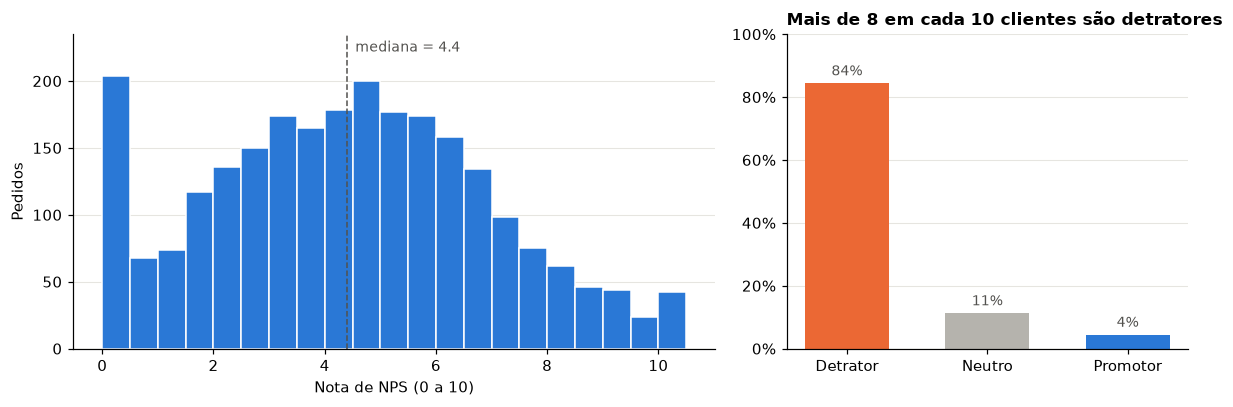

In [306]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax1.hist(df["nps_score"], bins=np.arange(0, 10.6, 0.5), color=COR_PRINCIPAL, edgecolor="white", linewidth=1)
ax1.axvline(df["nps_score"].median(), color="#52514e", linestyle="--", linewidth=1)
ax1.set_ylim(0, 235)
ax1.text(df["nps_score"].median() + 0.15, 222, f"mediana = {df['nps_score'].median():.1f}",
         fontsize=9, color="#52514e")
ax1.set_xlabel("Nota de NPS (0 a 10)")
ax1.set_ylabel("Pedidos")

pct_categoria = df["categoria_nps"].value_counts(normalize=True).reindex(ORDEM_CATEGORIAS) * 100
ax2.bar(pct_categoria.index, pct_categoria.values, color=[CORES_CATEGORIA[c] for c in pct_categoria.index], width=0.6)
rotular_barras(ax2)
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_title("Mais de 8 em cada 10 clientes são detratores")

plt.tight_layout()
salvar_figura(fig, "01_distribuicao_nps.png")
plt.show()

A maior parte das notas fica entre 2 e 6

### 1.2 NPS geral com intervalo de confiança

A base é uma amostra de 2.500 pedidos, então o NPS calculado aqui é uma estimativa. Por isso calculei intervalos de confiança de 95%, que mostram a faixa onde o valor verdadeiro provavelmente está.

Para as proporções de detratores e promotores usei o intervalo de Wilson, que é o recomendado para proporções. Para o NPS usei que cada cliente vira +1 (promotor), 0 (neutro) ou -1 (detrator). A média dessa variável, vezes 100, é exatamente o NPS. Aí dá para usar o intervalo de uma média, com o erro padrão e z = 1,96. Como a amostra é grande (2.500 pedidos), a média segue aproximadamente uma normal pelo teorema central do limite, mesmo a variável tendo só três valores.

In [307]:
n_pedidos = len(df)
n_detratores = (df["categoria_nps"] == "Detrator").sum()
n_promotores = (df["categoria_nps"] == "Promotor").sum()

ic_det = proportion_confint(n_detratores, n_pedidos, alpha=ALFA, method="wilson")
ic_pro = proportion_confint(n_promotores, n_pedidos, alpha=ALFA, method="wilson")
nps_geral, nps_inferior, nps_superior = ic_nps(df["categoria_nps"])

print(f"Detratores: {n_detratores / n_pedidos:.1%}  (IC 95%: {ic_det[0]:.1%} a {ic_det[1]:.1%})")
print(f"Promotores: {n_promotores / n_pedidos:.1%}  (IC 95%: {ic_pro[0]:.1%} a {ic_pro[1]:.1%})")
print(f"NPS: {nps_geral:.1f}  (IC 95%: {nps_inferior:.1f} a {nps_superior:.1f})")

Detratores: 84.4%  (IC 95%: 82.9% a 85.7%)
Promotores: 4.4%  (IC 95%: 3.7% a 5.3%)
NPS: -80.0  (IC 95%: -81.9 a -78.0)


O NPS fica entre -82 e -78 com 95% de confiança. Mesmo no melhor cenário do intervalo ele fica abaixo de -78. Para comparação, qualquer NPS negativo já quer dizer que a empresa tem mais clientes falando mal do que bem. Não é uma oscilação, é um problema real.

### 1.3 A nota segue uma distribuição normal?

Isso define quais testes usar. Se a nota não for normal, os testes paramétricos ficam menos confiáveis e o mais seguro é usar os não paramétricos.

In [308]:
estat_shapiro, p_shapiro = stats.shapiro(df["nps_score"])
print(f"Shapiro-Wilk: W = {estat_shapiro:.4f} | p-valor = {p_shapiro:.2e}")
print(f"Assimetria: {stats.skew(df['nps_score']):.3f} | Curtose: {stats.kurtosis(df['nps_score']):.3f}")
print("Rejeita normalidade?", p_shapiro < ALFA)

Shapiro-Wilk: W = 0.9817 | p-valor = 2.14e-17
Assimetria: 0.110 | Curtose: -0.609
Rejeita normalidade? True


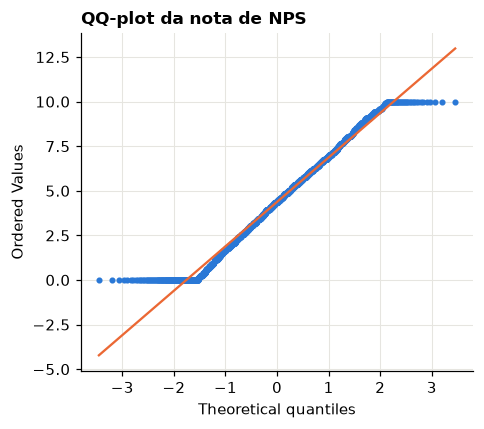

In [309]:
fig, ax = plt.subplots(figsize=(4.5, 4))
stats.probplot(df["nps_score"], dist="norm", plot=ax)
ax.get_lines()[0].set(markerfacecolor=COR_PRINCIPAL, markeredgecolor=COR_PRINCIPAL, markersize=3)
ax.get_lines()[1].set(color=COR_DESTAQUE)
ax.set_title("QQ-plot da nota de NPS")
ax.grid(True, axis="both")
plt.tight_layout()
plt.show()

O Shapiro-Wilk rejeita a normalidade e o QQ-plot mostra os desvios nas pontas (principalmente o acúmulo de notas zero, que forma um degrau no começo). Além disso, as variáveis operacionais são contagens (dias, contatos), que também não são normais. Por isso, no resto da análise uso como padrão Spearman para correlação, Mann-Whitney para comparar dois grupos e Kruskal-Wallis para três ou mais. Em região faço também a ANOVA para comparar os dois resultados.

## 2. Quais fatores mais se relacionam com a nota?

Primeiro uma visão geral: a correlação de Spearman de cada variável com a nota, com o p-valor do teste.

In [310]:
variaveis_explicativas = [
    "delivery_delay_days", "complaints_count", "customer_service_contacts", "resolution_time_days",
    "delivery_time_days", "delivery_attempts", "freight_value", "pct_frete_pedido", "order_value",
    "discount_value", "items_quantity", "payment_installments", "customer_age", "customer_tenure_months",
]

linhas = []
for variavel in variaveis_explicativas:
    rho, p_valor = stats.spearmanr(df[variavel], df["nps_score"])
    linhas.append({"variavel": variavel, "spearman": rho, "p_valor": p_valor})

tabela_correlacao = pd.DataFrame(linhas).sort_values("spearman", key=abs, ascending=False)
tabela_correlacao["significativa"] = np.where(tabela_correlacao["p_valor"] < ALFA, "sim", "não")
tabela_correlacao

,variavel,spearman,p_valor,significativa
0,delivery_delay_days,-0.586,0.000,sim
1,complaints_count,-0.490,0.000,sim
2,customer_service_contacts,-0.336,0.000,sim
3,resolution_time_days,-0.190,0.000,sim
7,pct_frete_pedido,-0.045,0.025,sim
6,freight_value,-0.040,0.048,sim
8,order_value,0.036,0.073,não
11,payment_installments,0.027,0.183,não
5,delivery_attempts,0.026,0.189,não
13,customer_tenure_months,-0.012,0.560,não


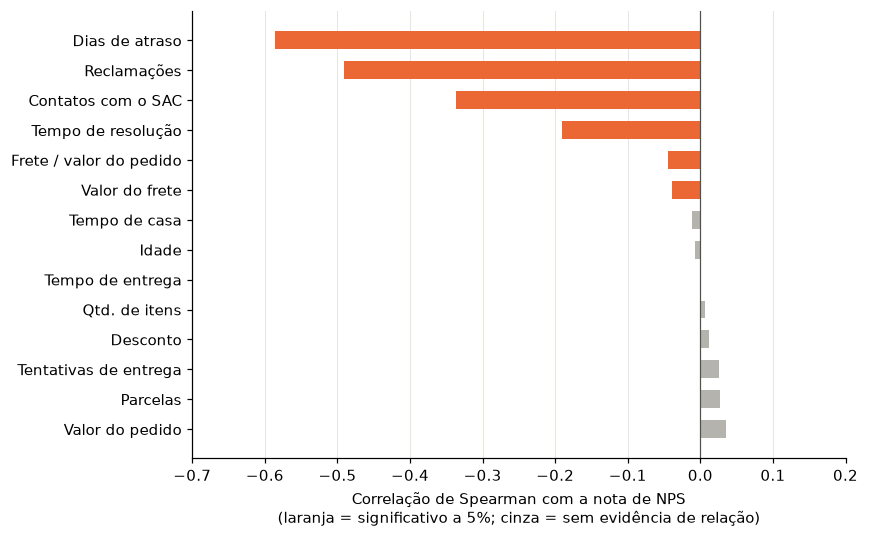

In [311]:
nomes_amigaveis = {
    "delivery_delay_days": "Dias de atraso",
    "complaints_count": "Reclamações",
    "customer_service_contacts": "Contatos com o SAC",
    "resolution_time_days": "Tempo de resolução",
    "delivery_time_days": "Tempo de entrega",
    "delivery_attempts": "Tentativas de entrega",
    "freight_value": "Valor do frete",
    "pct_frete_pedido": "Frete / valor do pedido",
    "order_value": "Valor do pedido",
    "discount_value": "Desconto",
    "items_quantity": "Qtd. de itens",
    "payment_installments": "Parcelas",
    "customer_age": "Idade",
    "customer_tenure_months": "Tempo de casa",
}

dados_grafico = tabela_correlacao.sort_values("spearman", ascending=False)
cores = [COR_DESTAQUE if s == "sim" else COR_CINZA for s in dados_grafico["significativa"]]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(dados_grafico["variavel"].map(nomes_amigaveis), dados_grafico["spearman"], color=cores, height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_xlim(-0.7, 0.2)
ax.set_xlabel("Correlação de Spearman com a nota de NPS\n(laranja = significativo a 5%; cinza = sem evidência de relação)")
plt.tight_layout()
salvar_figura(fig, "02_correlacao_com_nps.png")
plt.show()

O resultado é bem concentrado. Quatro variáveis têm correlação negativa clara com a nota, todas ligadas a coisas que deram errado na jornada: atraso, reclamações, contatos com o SAC e tempo de resolução. Todo o resto (valor, frete, desconto, parcelas, idade, tempo de casa, até o tempo de entrega) fica perto de zero.

`freight_value` e `pct_frete_pedido` aparecem como significativos, mas com correlação em torno de -0,04. Com 2.500 pedidos até um efeito minúsculo passa no teste, então aqui vale olhar o tamanho do efeito e não só o p-valor. Para o negócio, isso é praticamente nada.

Também vale olhar como as variáveis se relacionam entre si, porque se duas andam juntas elas podem estar contando a mesma história:

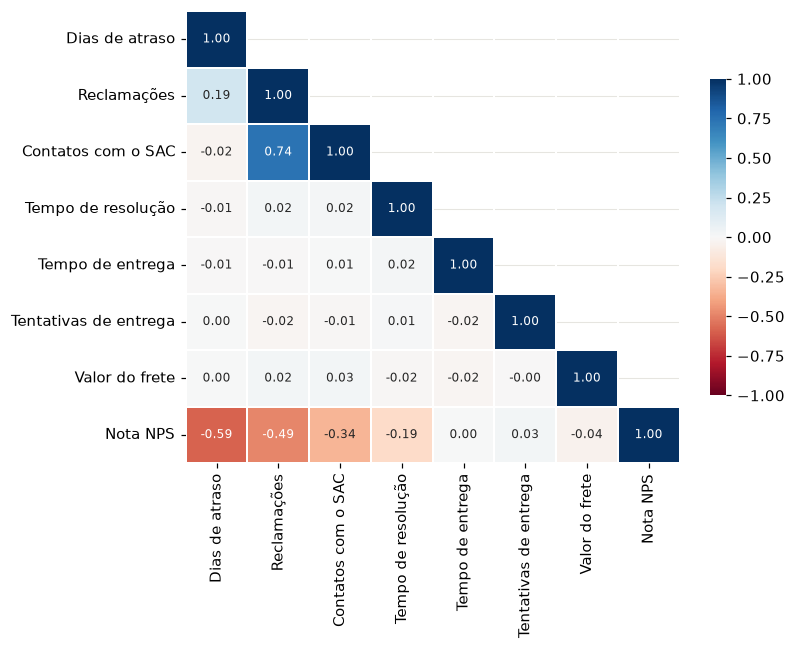

In [312]:
colunas_heatmap = variaveis_explicativas[:7] + ["nps_score"]
matriz = df[colunas_heatmap].corr(method="spearman")
matriz.index = matriz.columns = [nomes_amigaveis.get(c, "Nota NPS") for c in colunas_heatmap]

fig, ax = plt.subplots(figsize=(7.5, 6))
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax, annot_kws={"size": 8})
plt.tight_layout()
salvar_figura(fig, "03_matriz_correlacao.png")
plt.show()

Reclamações andam junto com contatos com o SAC (0,74)

Dois pontos importantes aqui:

- As variáveis operacionais quase não se correlacionam entre si (atraso não tem relação com contatos, por exemplo). Isso quer dizer que cada uma traz uma informação diferente sobre o pedido.
- A exceção é reclamações x contatos com o SAC (0,74). Faz sentido: quem reclama precisa falar com o atendimento.

## 3. Entrega: atraso é o principal fator

### 3.1 Atrasar pesa, demorar não

Antes de olhar o atraso em detalhe, uma comparação que eu acho que resume bem a história: a nota média por tempo de entrega e por dias de atraso, na mesma escala.

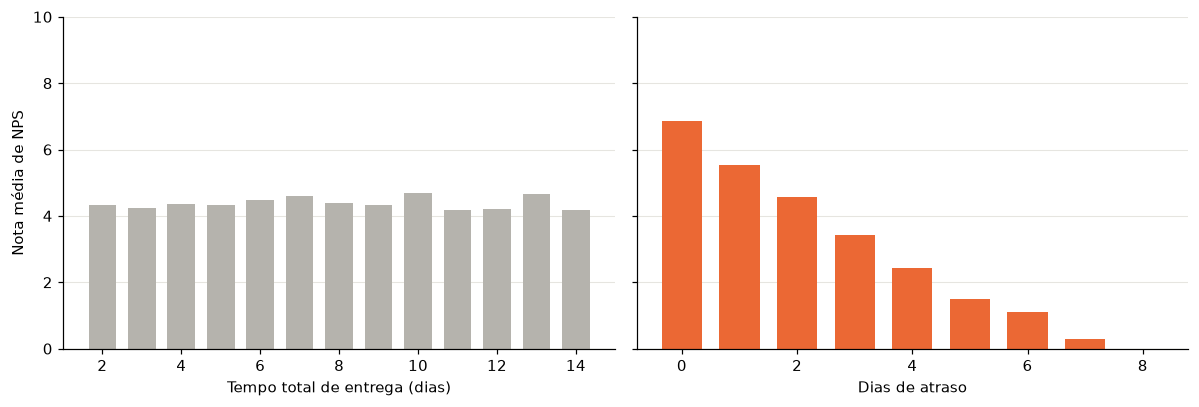

Tempo de entrega x nota: rho = 0.000 (p = 0.988)
Dias de atraso x nota:   rho = -0.586 (p = 1.09e-230)


In [313]:
nota_por_tempo = df.groupby("delivery_time_days")["nps_score"].mean()
nota_por_atraso = df.groupby("delivery_delay_days")["nps_score"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax1.bar(nota_por_tempo.index, nota_por_tempo.values, color=COR_CINZA, width=0.7)
ax1.set_xlabel("Tempo total de entrega (dias)")
ax1.set_ylabel("Nota média de NPS")
ax1.set_ylim(0, 10)

ax2.bar(nota_por_atraso.index, nota_por_atraso.values, color=COR_DESTAQUE, width=0.7)
ax2.set_xlabel("Dias de atraso")
plt.tight_layout()
salvar_figura(fig, "04_tempo_vs_atraso.png")
plt.show()

rho_tempo, p_tempo = stats.spearmanr(df["delivery_time_days"], df["nps_score"])
rho_atraso, p_atraso = stats.spearmanr(df["delivery_delay_days"], df["nps_score"])
print(f"Tempo de entrega x nota: rho = {rho_tempo:.3f} (p = {p_tempo:.3f})")
print(f"Dias de atraso x nota:   rho = {rho_atraso:.3f} (p = {p_atraso:.2e})")

- Entregas de 2 ou de 14 dias têm a mesma nota.
- Cada dia de atraso tira cerca de 1 ponto da nota

Esse é provavelmente o achado mais útil para a logística: o cliente não pune a entrega demorada, pune a promessa quebrada. Um pedido que leva 14 dias e chega no prazo tem a mesma nota de um que leva 2. O que derruba a nota é chegar depois do combinado.

Na prática isso abre uma alavanca que custa pouco: prometer prazos mais realistas. Um prazo prometido um pouco maior e cumprido tende a gerar mais satisfação do que um prazo agressivo que atrasa.

### 3.2 Testando a diferença entre no prazo e atrasado

In [314]:
nota_no_prazo = df.loc[df["entregue_no_prazo"] == 1, "nps_score"]
nota_atrasado = df.loc[df["entregue_no_prazo"] == 0, "nps_score"]

u, p_mw = stats.mannwhitneyu(nota_no_prazo, nota_atrasado, alternative="two-sided")
print(f"No prazo: {len(nota_no_prazo)} pedidos | mediana {nota_no_prazo.median():.1f}")
print(f"Atrasado: {len(nota_atrasado)} pedidos | mediana {nota_atrasado.median():.1f}")
print(f"Mann-Whitney U = {u:,.0f} | p-valor = {p_mw:.2e}")

grupos_atraso = [g["nps_score"].values for _, g in df.groupby("faixa_atraso", observed=True)]
h, p_kw = stats.kruskal(*grupos_atraso)
print(f"\nKruskal-Wallis entre as faixas de atraso: H = {h:.1f} | p-valor = {p_kw:.2e}")

No prazo: 277 pedidos | mediana 6.8
Atrasado: 2223 pedidos | mediana 4.1
Mann-Whitney U = 497,578 | p-valor = 5.87e-63

Kruskal-Wallis entre as faixas de atraso: H = 859.2 | p-valor = 1.14e-184


Em termos de detratores, com intervalo de confiança de Wilson:

In [315]:
tabela_prazo = ic_detratores(df, "entregue_no_prazo").rename(index={0: "Atrasado", 1: "No prazo"})
tabela_prazo

,pedidos,detratores,pct_detratores,ic_inferior,ic_superior
entregue_no_prazo,,,,,
Atrasado,2223,1966,88.400,87.000,89.700
No prazo,277,143,51.600,45.800,57.400


No prazo, entre 46% e 57% dos clientes são detratores. Com atraso, entre 87% e 90%. Os intervalos estão muito longe um do outro, então a diferença não tem como ser fruto do acaso da amostra.

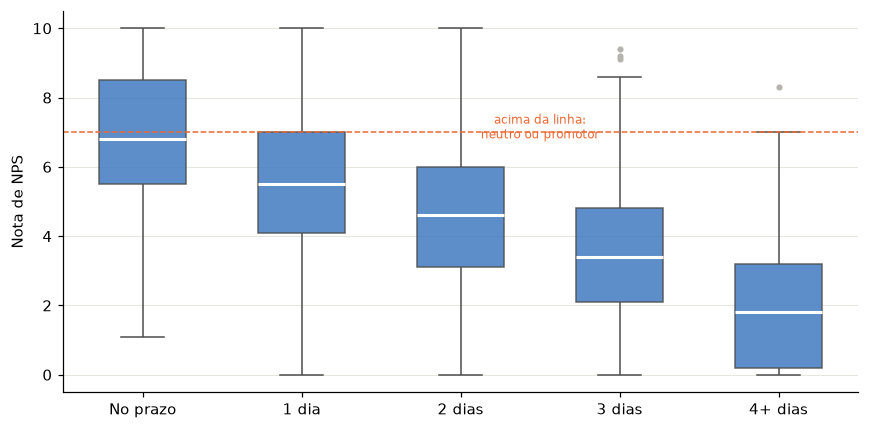

In [316]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="faixa_atraso", y="nps_score", color=COR_PRINCIPAL, width=0.55,
            boxprops={"alpha": 0.85}, medianprops={"color": "white", "linewidth": 2},
            flierprops={"markersize": 3, "markerfacecolor": COR_CINZA, "markeredgecolor": COR_CINZA}, ax=ax)
ax.axhline(7.0, color=COR_DESTAQUE, linestyle="--", linewidth=1)
ax.text(2.5, 6.7, "acima da linha:\nneutro ou promotor", fontsize=8, color=COR_DESTAQUE, ha="center", va="bottom")
ax.set_xlabel("")
ax.set_ylabel("Nota de NPS")
plt.tight_layout()
salvar_figura(fig, "05_boxplot_atraso.png")
plt.show()

A partir de 2 dias de atraso, a caixa inteira fica na zona de detrator

### 3.3 Existe um ponto de ruptura?

Para achar o ponto de ruptura, olhei o percentual de detratores para cada dia de atraso, com o intervalo de confiança de Wilson (para não tirar conclusão de grupos muito pequenos, como 7 e 8 dias, que têm 14 e 3 pedidos).

In [317]:
ruptura = df.groupby("delivery_delay_days").agg(
    pedidos=("flag_detrator", "size"),
    detratores=("flag_detrator", "sum"),
)
ruptura["pct_detratores"] = ruptura["detratores"] / ruptura["pedidos"] * 100
limites = proportion_confint(ruptura["detratores"], ruptura["pedidos"], alpha=ALFA, method="wilson")
ruptura["ic_inferior"] = limites[0] * 100
ruptura["ic_superior"] = limites[1] * 100
ruptura["nota_media"] = df.groupby("delivery_delay_days")["nps_score"].mean()
ruptura.round(1)

,pedidos,detratores,pct_detratores,ic_inferior,ic_superior,nota_media
delivery_delay_days,,,,,,
0,277,143,51.600,45.800,57.400,6.900
1,615,455,74.000,70.400,77.300,5.500
2,646,568,87.900,85.200,90.200,4.600
3,525,508,96.800,94.900,98.000,3.400
4,270,268,99.300,97.300,99.800,2.400
5,116,116,100.000,96.800,100.000,1.500
6,34,34,100.000,89.800,100.000,1.100
7,14,14,100.000,78.500,100.000,0.300
8,3,3,100.000,43.900,100.000,0.000


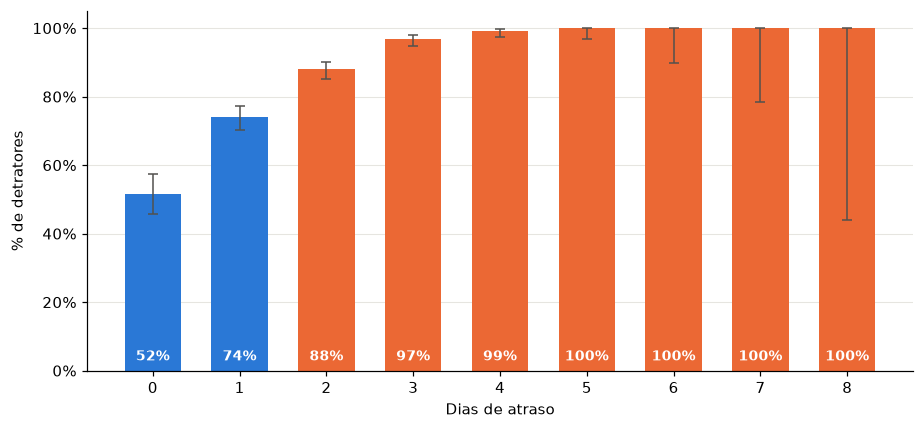

In [318]:
fig, ax = plt.subplots(figsize=(8.5, 4))
cores = [COR_DESTAQUE if pct >= 80 else COR_PRINCIPAL for pct in ruptura["pct_detratores"]]
ax.bar(ruptura.index, ruptura["pct_detratores"], color=cores, width=0.65)
# clip evita valores negativos minúsculos por arredondamento quando o grupo tem 100% de detratores
erro = [(ruptura["pct_detratores"] - ruptura["ic_inferior"]).clip(lower=0),
        (ruptura["ic_superior"] - ruptura["pct_detratores"]).clip(lower=0)]
ax.errorbar(ruptura.index, ruptura["pct_detratores"], yerr=erro, fmt="none", ecolor="#52514e", elinewidth=1, capsize=3)
for x, pct in zip(ruptura.index, ruptura["pct_detratores"]):
    ax.text(x, 3, f"{pct:.0f}%", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticks(ruptura.index)
ax.set_xlabel("Dias de atraso")
ax.set_ylabel("% de detratores")
plt.tight_layout()
salvar_figura(fig, "06_ponto_ruptura_atraso.png")
plt.show()

Com 2 dias de atraso, quase 9 em cada 10 viram detratores; com 4, praticamente todos

A curva mostra dois pontos claros:

- 2 dias de atraso é onde a experiência quebra: o percentual de detratores chega a 88% (IC 95%: 85% a 90%) e a nota média cai abaixo de 5. Com 1 dia ainda sobra alguma margem para recuperar o cliente (74% de detratores, 7% de promotores).
- 4 dias ou mais é praticamente perda certa: 99% a 100% de detratores e nenhum promotor.

Mesmo no prazo metade dos clientes (52%) ainda é detratora. Ou seja, entregar no prazo é necessário mas não é suficiente.

Para confirmar que a associação não é acaso, fiz também o teste Qui-Quadrado entre faixa de atraso e categoria do NPS:

In [319]:
tabela_contingencia = pd.crosstab(df["faixa_atraso"], df["categoria_nps"])
qui2, p_qui2, gl, esperado = stats.chi2_contingency(tabela_contingencia)
print(tabela_contingencia, "\n")
print(f"Qui-Quadrado = {qui2:.1f} | graus de liberdade = {gl} | p-valor = {p_qui2:.2e}")
print("\nPromotores esperados se não houvesse relação:")
print(pd.DataFrame(esperado, index=tabela_contingencia.index, columns=tabela_contingencia.columns)["Promotor"].round(1))

categoria_nps  Detrator  Neutro  Promotor
faixa_atraso                             
No prazo            143      84        50
1 dia               455     116        44
2 dias              568      65        13
3 dias              508      14         3
4+ dias             435       2         0 

Qui-Quadrado = 440.4 | graus de liberdade = 8 | p-valor = 4.22e-90

Promotores esperados se não houvesse relação:
faixa_atraso
No prazo   12.200
1 dia      27.100
2 dias     28.400
3 dias     23.100
4+ dias    19.200
Name: Promotor, dtype: float64


Se atraso e categoria fossem independentes, era de se esperar uns 19 promotores entre os pedidos com 4 ou mais dias de atraso. Tem zero. No prazo era de se esperar 12 e tem 50. Hipótese 1 confirmada.

- atraso na entrega é o fator que mais derruba a nota, e existe um número de dias a partir do qual quase todo mundo vira detrator.

### 3.4 Tentativas de entrega

In [320]:
resumo_tentativas = resumo_por_grupo(df, "delivery_attempts")
grupos_tentativas = [g["nps_score"].values for _, g in df.groupby("delivery_attempts")]
h_tent, p_tent = stats.kruskal(*grupos_tentativas)
print(f"Kruskal-Wallis: H = {h_tent:.2f} | p-valor = {p_tent:.3f}")

# olhando só os pedidos entregues no prazo, que era o ponto da hipótese
no_prazo = df[df["entregue_no_prazo"] == 1]
h_tent2, p_tent2 = stats.kruskal(*[g["nps_score"].values for _, g in no_prazo.groupby("delivery_attempts")])
print(f"Só pedidos no prazo: H = {h_tent2:.2f} | p-valor = {p_tent2:.3f}")
resumo_tentativas

Kruskal-Wallis: H = 4.44 | p-valor = 0.108
Só pedidos no prazo: H = 2.18 | p-valor = 0.337


,pedidos,nota_media,pct_detratores,pct_promotores,nps
delivery_attempts,,,,,
1,824,4.350,84.220,4.000,-80.220
2,838,4.260,86.750,3.220,-83.530
3,838,4.520,82.100,5.970,-76.130


Não há diferença entre 1, 2 ou 3 tentativas de entrega, nem olhando só os pedidos que chegaram no prazo. Hipótese 2 não se confirma. É um resultado um pouco contraintuitivo (eu esperava que o cliente ficasse irritado com a transportadora voltando várias vezes), mas nesta base o que importa é a data em que o pedido chega, não quantas vezes tentaram.

- ~~mais tentativas de entrega pioram a nota, mesmo sem atraso.~~

## 4. Atendimento: contatos, resolução e reclamações

### 4.1 Contatos com o SAC e tempo de resolução

In [321]:
resumo_contatos = resumo_por_grupo(df, "faixa_contatos")
resumo_resolucao = resumo_por_grupo(df, "faixa_resolucao")

h_cont, p_cont = stats.kruskal(*[g["nps_score"].values for _, g in df.groupby("faixa_contatos", observed=True)])
h_res, p_res = stats.kruskal(*[g["nps_score"].values for _, g in df.groupby("faixa_resolucao", observed=True)])
print(f"Contatos   - Kruskal-Wallis: H = {h_cont:.1f} | p-valor = {p_cont:.2e}")
print(f"Resolução  - Kruskal-Wallis: H = {h_res:.1f} | p-valor = {p_res:.2e}")
display(resumo_contatos)
display(resumo_resolucao)

Contatos   - Kruskal-Wallis: H = 288.9 | p-valor = 2.50e-62
Resolução  - Kruskal-Wallis: H = 83.2 | p-valor = 6.24e-18


,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_contatos,,,,,
0,554,5.540,70.760,10.290,-60.470
1,816,4.660,83.950,4.410,-79.530
2,640,4.120,88.590,2.190,-86.410
3+,490,2.940,94.900,0.610,-94.290


,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_resolucao,,,,,
0-2 dias,629,5.040,77.740,7.470,-70.270
3-5 dias,619,4.510,82.550,5.170,-77.380
6-8 dias,637,4.180,86.810,2.980,-83.830
9+ dias,615,3.780,90.410,1.950,-88.460


In [322]:
# % de detratores por número de contatos, com IC de Wilson
ic_detratores(df, "faixa_contatos")

,pedidos,detratores,pct_detratores,ic_inferior,ic_superior
faixa_contatos,,,,,
0,554,392,70.800,66.800,74.400
1,816,685,83.900,81.300,86.300
2,640,567,88.600,85.900,90.800
3+,490,465,94.900,92.600,96.500


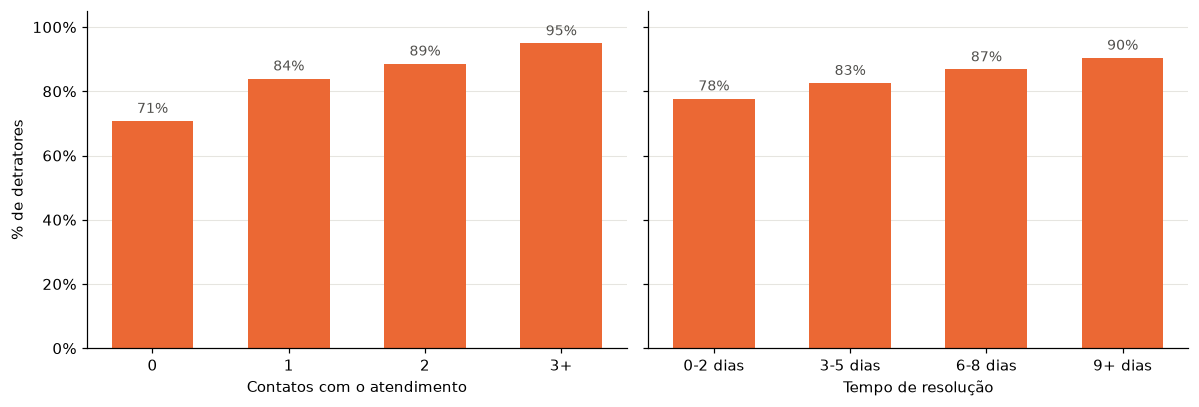

In [323]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

ax1.bar(resumo_contatos.index.astype(str), resumo_contatos["pct_detratores"], color=COR_DESTAQUE, width=0.6)
rotular_barras(ax1)
ax1.set_xlabel("Contatos com o atendimento")
ax1.set_ylabel("% de detratores")
ax1.set_ylim(0, 105)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())

ax2.bar(resumo_resolucao.index.astype(str), resumo_resolucao["pct_detratores"], color=COR_DESTAQUE, width=0.6)
rotular_barras(ax2)
ax2.set_xlabel("Tempo de resolução")
plt.tight_layout()
salvar_figura(fig, "07_atendimento.png")
plt.show()

Os dois fatores pioram a nota e os dois testes são significativos. O efeito dos contatos é mais forte: sem nenhum contato são 71% de detratores (IC 95%: 67% a 74%), com 3 ou mais são 95% (IC 95%: 93% a 97%). Só os intervalos de 1 e 2 contatos se sobrepõem um pouco; os demais ficam separados, o que reforça que cada contato a mais pesa. O tempo de resolução tem um efeito mais gradual (de 78% para 90%). Hipótese 3 confirmada, com mais peso para o número de contatos do que para a demora.

- Cada contato extra com o SAC aumenta os detratores
- Resolução demorada também pesa, mas menos

Uma leitura de negócio: cada contato é um sinal de que alguma coisa não foi resolvida da primeira vez. Melhorar a resolução no primeiro contato provavelmente ajuda mais do que só reduzir prazo de resposta.

### 4.2 Atraso e atendimento juntos

Como atraso e contatos quase não se correlacionam, vale ver o efeito combinado. O mapa abaixo mostra o percentual de detratores em cada combinação:

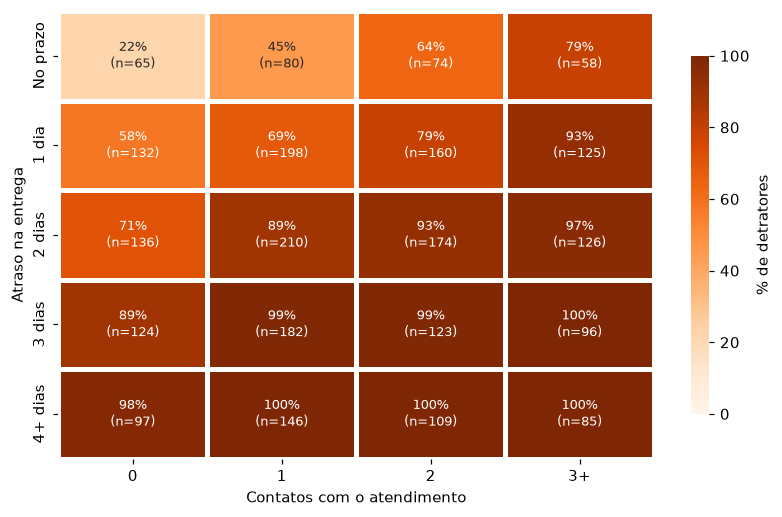

In [324]:
mapa = pd.pivot_table(df, values="flag_detrator", index="faixa_atraso", columns="faixa_contatos",
                      aggfunc="mean", observed=True) * 100
contagem = pd.pivot_table(df, values="flag_detrator", index="faixa_atraso", columns="faixa_contatos",
                          aggfunc="size", observed=True)
rotulos = mapa.round(0).astype(int).astype(str) + "%\n(n=" + contagem.astype(str) + ")"

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(mapa, annot=rotulos, fmt="", cmap="Oranges", vmin=0, vmax=100, linewidths=2, linecolor="white",
            cbar_kws={"label": "% de detratores", "shrink": 0.8}, ax=ax, annot_kws={"size": 8.5})
ax.set_xlabel("Contatos com o atendimento")
ax.set_ylabel("Atraso na entrega")
plt.tight_layout()
salvar_figura(fig, "08_atraso_x_contatos.png")
plt.show()

Esse mapa é bom porque resume a operação em uma figura:

- Pedido no prazo e sem contato com o SAC: 22% de detratores. É a experiência redonda.
- Basta um dos dois dar errado para a situação mudar: no prazo mas com 2 contatos já são 64%; 2 dias de atraso e nenhum contato, 71%.
- Com atraso e contato juntos o percentual passa de 90% rápido.

Os efeitos se somam. Isso sugere que a logística e o atendimento precisam ser trabalhados juntos, e que um pedido atrasado que gera contato no SAC é o caso mais urgente para uma ação preventiva.

### 4.3 E as reclamações?

No notebook 01 deixei `complaints_count` "em avaliação", porque a média de 4 reclamações por pedido parece alta e não está claro de onde vem a contagem.

In [325]:
print("Média de reclamações por número de contatos com o SAC:")
print(df.groupby("customer_service_contacts")["complaints_count"].mean().round(2).to_string())
print("\nMédia de reclamações por faixa de atraso:")
print(df.groupby("faixa_atraso", observed=True)["complaints_count"].mean().round(2).to_string())
print(f"\nPedidos sem nenhum contato e com 3+ reclamações: {((df['customer_service_contacts'] == 0) & (df['complaints_count'] >= 3)).sum()}")

Média de reclamações por número de contatos com o SAC:
customer_service_contacts
0    2.510
1    3.570
2    4.650
3    5.780
4    7.020
5    7.650
6    9.140
7   10.000

Média de reclamações por faixa de atraso:
faixa_atraso
No prazo   2.960
1 dia      4.140
2 dias     4.220
3 dias     4.350
4+ dias    4.560

Pedidos sem nenhum contato e com 3+ reclamações: 258


In [326]:
# quanto as reclamações acrescentam além do que atraso, contatos e resolução já explicam?
modelo_sem = smf.ols("nps_score ~ delivery_delay_days + customer_service_contacts + resolution_time_days", data=df).fit()
modelo_com = smf.ols("nps_score ~ delivery_delay_days + customer_service_contacts + resolution_time_days + complaints_count",
                     data=df).fit()
print(f"R² sem reclamações: {modelo_sem.rsquared:.3f}")
print(f"R² com reclamações: {modelo_com.rsquared:.3f}")
print(f"Coeficiente de contatos sem reclamações: {modelo_sem.params['customer_service_contacts']:.2f}")
print(f"Coeficiente de contatos com reclamações: {modelo_com.params['customer_service_contacts']:.2f}")

R² sem reclamações: 0.528
R² com reclamações: 0.556
Coeficiente de contatos sem reclamações: -0.74
Coeficiente de contatos com reclamações: -0.32


O que dá para concluir:

- As reclamações crescem quase em linha reta com os contatos (de 2,5 sem contato para 10 com 7 contatos) e também sobem com o atraso. Ou seja, a coluna é em boa parte um reflexo de atraso e atendimento.
- Existem 258 pedidos com 3 ou mais reclamações e nenhum contato com o SAC, o que reforça que a contagem não é só deste pedido.
- Colocar reclamações no modelo de regressão aumenta pouco o R² (de 0,53 para 0,56) e rouba metade do efeito dos contatos.

Decisão: na história para o negócio trato reclamações como um sintoma do atraso e do atendimento, e não como causa. Para o modelo preditivo, a recomendação é não usar como variável principal, porque não sei se ela está disponível antes da pesquisa. Se for usada, deve ser em um cenário separado.

## 5. Pedido: valor, frete, desconto e parcelamento

In [327]:
testes_pedido = []
for variavel, nome in [("pct_frete_pedido", "Frete / valor do pedido"), ("freight_value", "Valor do frete"),
                       ("discount_value", "Desconto"), ("order_value", "Valor do pedido"),
                       ("items_quantity", "Qtd. de itens"), ("payment_installments", "Parcelas")]:
    quartis = pd.qcut(df[variavel], q=4, duplicates="drop")
    h, p = stats.kruskal(*[g["nps_score"].values for _, g in df.groupby(quartis, observed=True)])
    nps_por_quartil = df.groupby(quartis, observed=True)["categoria_nps"].apply(calcular_nps)
    testes_pedido.append({
        "variavel": nome,
        "kruskal_p_valor": p,
        "nps_menor_quartil": nps_por_quartil.iloc[0],
        "nps_maior_quartil": nps_por_quartil.iloc[-1],
    })
pd.DataFrame(testes_pedido).round(3)

,variavel,kruskal_p_valor,nps_menor_quartil,nps_maior_quartil
0,Frete / valor do pedido,0.135,-78.240,-82.400
1,Valor do frete,0.133,-78.880,-81.250
2,Desconto,0.513,-80.320,-77.920
3,Valor do pedido,0.061,-83.520,-76.960
4,Qtd. de itens,0.462,-79.444,-80.702
5,Parcelas,0.170,-81.583,-78.879


Nenhuma variável do pedido muda a nota de forma relevante. O frete proporcional ao valor (que era a minha Hipótese 4) até tem um NPS um pouco pior no quartil mais caro, mas comparando os quartis a diferença não é significativa, e a correlação que apareceu na seção 2 é muito fraca. Hipotése não se confirma na prática: existe no máximo um sinal muito pequeno do frete, e nesta base o cliente não parece reagir a preço ou desconto, só à execução da entrega e do atendimento.

Para o negócio isso é relevante porque descarta algumas soluções que normalmente aparecem primeiro na mesa (dar desconto ou frete grátis para compensar a experiência). Pelos dados, elas não mexeriam no NPS.

- ~~frete alto em relação ao valor do pedido pesa negativamente; desconto ajuda pouco.~~

## 6. Perfil do cliente: quem dá nota mais alta ou mais baixa?

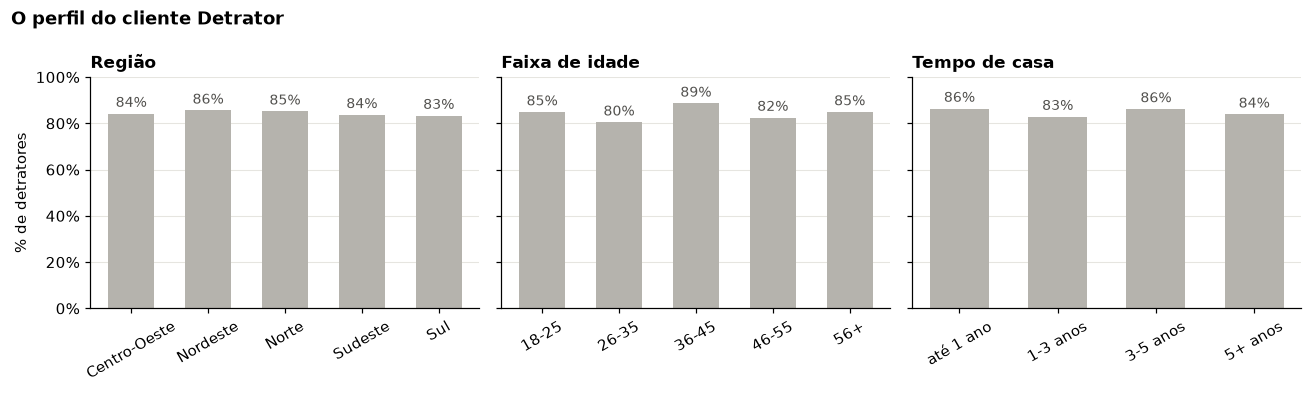

In [328]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (coluna, titulo) in zip(eixos, [("customer_region", "Região"), ("faixa_idade", "Faixa de idade"),
                                        ("faixa_tempo_casa", "Tempo de casa")]):
    resumo = resumo_por_grupo(df, coluna)
    ax.bar(resumo.index.astype(str), resumo["pct_detratores"], color=COR_CINZA, width=0.6)
    rotular_barras(ax)
    ax.set_title(titulo)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.tick_params(axis="x", rotation=30)
eixos[0].set_ylabel("% de detratores")
fig.suptitle("O perfil do cliente Detrator", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
salvar_figura(fig, "09_perfil_cliente.png")
plt.show()

In [329]:
# região: ANOVA e Kruskal-Wallis, para comparar
grupos_regiao = [g["nps_score"].values for _, g in df.groupby("customer_region")]
f_anova, p_anova = stats.f_oneway(*grupos_regiao)
h_reg, p_reg = stats.kruskal(*grupos_regiao)
qui2_reg, p_qui2_reg, _, _ = stats.chi2_contingency(pd.crosstab(df["customer_region"], df["categoria_nps"]))
print(f"Região - ANOVA:          F = {f_anova:.2f} | p-valor = {p_anova:.3f}")
print(f"Região - Kruskal-Wallis: H = {h_reg:.2f} | p-valor = {p_reg:.3f}")
print(f"Região - Qui-Quadrado:   X² = {qui2_reg:.2f} | p-valor = {p_qui2_reg:.3f}")

for coluna, nome in [("faixa_idade", "Idade"), ("faixa_tempo_casa", "Tempo de casa")]:
    h, p = stats.kruskal(*[g["nps_score"].values for _, g in df.groupby(coluna, observed=True)])
    print(f"{nome:13s} - Kruskal-Wallis: H = {h:.2f} | p-valor = {p:.3f}")

# Hipótese 5 fala de tolerância: clientes antigos perdoariam mais um atraso?
atrasados = df[df["delivery_delay_days"] >= 2]
h_tol, p_tol = stats.kruskal(*[g["nps_score"].values for _, g in atrasados.groupby("faixa_tempo_casa", observed=True)])
print(f"\nSó pedidos com 2+ dias de atraso, por tempo de casa: H = {h_tol:.2f} | p-valor = {p_tol:.3f}")
resumo_por_grupo(atrasados, "faixa_tempo_casa")

Região - ANOVA:          F = 0.83 | p-valor = 0.508
Região - Kruskal-Wallis: H = 3.38 | p-valor = 0.497
Região - Qui-Quadrado:   X² = 3.52 | p-valor = 0.898
Idade         - Kruskal-Wallis: H = 7.62 | p-valor = 0.107
Tempo de casa - Kruskal-Wallis: H = 4.66 | p-valor = 0.199

Só pedidos com 2+ dias de atraso, por tempo de casa: H = 1.83 | p-valor = 0.609


,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_tempo_casa,,,,,
até 1 ano,155,3.420,94.840,0.650,-94.190
1-3 anos,322,3.630,94.720,0.930,-93.790
3-5 anos,314,3.520,93.950,0.640,-93.310
5+ anos,817,3.470,93.510,1.220,-92.290


Região, idade e tempo de casa não mostram diferença estatisticamente significativa na nota. Na região os três testes dão p-valor perto de 0,5 ou maior, e a diferença de nota média entre a melhor (Sul) e a pior (Centro-Oeste) é de só 0,3 ponto. Idade ficou com p-valor de 0,11, também acima de 5%. E clientes antigos não perdoam mais um atraso do que clientes novos. Hipótese 5 e Hipótese 6 não se confirmam.

- ~~clientes com mais tempo de casa são mais tolerantes.~~
- ~~a região influencia a nota.~~

Respondendo a pergunta 4 do desafio: não é o tipo de cliente que define a nota, é o que acontece com o pedido dele. Um cliente jovem do Sul e um cliente de 60 anos do Norte reagem da mesma forma a um atraso de 3 dias. Isso é uma boa notícia para a empresa, porque significa que o problema é operacional e pode ser corrigido, e evita a tentação de segmentar clientes difíceis.

## 7. Juntando tudo: regressão linear múltipla

Para medir o peso de cada fator ao mesmo tempo (controlando pelos outros), ajustei uma regressão linear múltipla com todas as variáveis que estariam disponíveis antes da pesquisa. Ficam de fora as colunas com vazamento e as reclamações, pela decisão da seção 4.3.

O objetivo aqui não é prever, mas traduzir os efeitos em pontos de nota.

In [330]:
formula = ("nps_score ~ delivery_delay_days + customer_service_contacts + resolution_time_days"
           " + delivery_time_days + delivery_attempts + freight_value + order_value + discount_value"
           " + items_quantity + payment_installments + customer_age + customer_tenure_months + C(customer_region)")
modelo_ols = smf.ols(formula, data=df).fit()

resultado = pd.DataFrame({
    "coeficiente": modelo_ols.params,
    "ic_inferior": modelo_ols.conf_int()[0],
    "ic_superior": modelo_ols.conf_int()[1],
    "p_valor": modelo_ols.pvalues,
}).drop("Intercept")
resultado["significativo"] = np.where(resultado["p_valor"] < ALFA, "sim", "não")
print(f"R²: {modelo_ols.rsquared:.3f} | R² ajustado: {modelo_ols.rsquared_adj:.3f} | n = {int(modelo_ols.nobs)}")
resultado.sort_values("p_valor").round(4)

R²: 0.534 | R² ajustado: 0.531 | n = 2500


,coeficiente,ic_inferior,ic_superior,p_valor,significativo
delivery_delay_days,-1.051,-1.097,-1.004,0.000,sim
customer_service_contacts,-0.742,-0.796,-0.686,0.000,sim
resolution_time_days,-0.143,-0.162,-0.123,0.000,sim
order_value,0.000,0.000,0.001,0.000,sim
C(customer_region)[T.Sul],0.259,0.044,0.474,0.018,sim
freight_value,-0.006,-0.012,-0.001,0.025,sim
delivery_attempts,0.090,0.007,0.173,0.034,sim
payment_installments,0.014,-0.008,0.035,0.209,não
C(customer_region)[T.Sudeste],0.131,-0.084,0.346,0.233,não
C(customer_region)[T.Nordeste],0.113,-0.105,0.332,0.310,não


A regressão confirma o que os gráficos mostraram, agora com números:

- Cada dia de atraso tira cerca de 1 ponto da nota (coeficiente perto de -1,05), mantendo todo o resto igual.
- Cada contato extra com o SAC tira cerca de 0,7 ponto.
- Cada dia a mais de resolução tira cerca de 0,14 ponto (uma semana a mais de resolução equivale a 1 ponto).
- Valor do pedido, valor do frete, tentativas de entrega e a região Sul passam no teste de 5% na regressão, mas com efeitos pequenos: R$ 500 a mais no pedido equivalem a +0,2 ponto, R$ 20 a mais de frete a -0,1 ponto, e cada tentativa extra a +0,09 ponto (o sinal é até o contrário do que eu esperava). O Sul aparece 0,26 ponto acima do Centro-Oeste, mas na comparação entre todas as regiões (ANOVA e Kruskal) a diferença não foi significativa. São o tipo de resultado isolado que pode ser erro tipo I, e mesmo se forem reais o tamanho é muito menor que o do atraso.
- O resto (tempo de entrega, desconto, itens, parcelas, idade, tempo de casa) fica com coeficiente próximo de zero e sem significância.

Só com essas variáveis operacionais o modelo explica pouco mais da metade da variação da nota (R² em torno de 0,53). O restante pode vir de coisas que a base não tem (qualidade do produto, expectativa do cliente, avaliação do site) ou de ruído na própria nota.

## 8. Análise de sensibilidade: e os pedidos inconsistentes?

No tratamento decidi manter os 121 pedidos com atraso maior que o tempo de entrega e os 35 com desconto maior que o valor. Refazendo os principais números sem eles:

In [331]:
df_consistente = df[(df["flag_atraso_maior_que_entrega"] == 0) & (df["flag_desconto_maior_que_valor"] == 0)]
print(f"Pedidos na base completa: {len(df)} | sem os inconsistentes: {len(df_consistente)}")

comparacao = pd.DataFrame({
    "base_completa": [
        calcular_nps(df["categoria_nps"]),
        stats.spearmanr(df["delivery_delay_days"], df["nps_score"])[0],
        stats.spearmanr(df["customer_service_contacts"], df["nps_score"])[0],
        smf.ols(formula, data=df).fit().params["delivery_delay_days"],
    ],
    "sem_inconsistentes": [
        calcular_nps(df_consistente["categoria_nps"]),
        stats.spearmanr(df_consistente["delivery_delay_days"], df_consistente["nps_score"])[0],
        stats.spearmanr(df_consistente["customer_service_contacts"], df_consistente["nps_score"])[0],
        smf.ols(formula, data=df_consistente).fit().params["delivery_delay_days"],
    ],
}, index=["NPS", "Spearman atraso", "Spearman contatos", "Coef. atraso (regressão)"])
display(comparacao.round(3))

print("% de detratores por faixa de atraso:")
pd.DataFrame({
    "base_completa": resumo_por_grupo(df, "faixa_atraso")["pct_detratores"],
    "sem_inconsistentes": resumo_por_grupo(df_consistente, "faixa_atraso")["pct_detratores"],
}).round(1)

Pedidos na base completa: 2500 | sem os inconsistentes: 2346


,base_completa,sem_inconsistentes
NPS,-79.960,-79.113
Spearman atraso,-0.586,-0.568
Spearman contatos,-0.336,-0.339
Coef. atraso (regressão),-1.051,-1.067


% de detratores por faixa de atraso:


,base_completa,sem_inconsistentes
faixa_atraso,,
No prazo,51.600,51.800
1 dia,74.000,74.100
2 dias,87.900,87.900
3 dias,96.800,96.900
4+ dias,99.500,99.400


Os números praticamente não mudam. A decisão de manter esses pedidos não afeta nenhuma conclusão.

## 9. Um olhar rápido sobre CSAT e recompra

Essas duas colunas não entram na busca por causas nem no modelo, mas vale mostrar por que, porque à primeira vista elas parecem os melhores preditores da base:

In [332]:
print("Spearman com a nota de NPS:")
for coluna in ["csat_internal_score", "repeat_purchase_30d"]:
    print(f"  {coluna}: {stats.spearmanr(df[coluna], df['nps_score'])[0]:.3f}")
print()
print(df.groupby("categoria_nps", observed=True)[["csat_internal_score", "repeat_purchase_30d"]].mean().round(2))

Spearman com a nota de NPS:
  csat_internal_score: 0.561
  repeat_purchase_30d: 0.489

               csat_internal_score  repeat_purchase_30d
categoria_nps                                          
Detrator                     2.540                0.000
Neutro                       4.770                0.380
Promotor                     6.040                1.000


O CSAT tem a maior correlação com o NPS de toda a base e a recompra separa perfeitamente detratores de promotores. Mas as duas são medidas da mesma satisfação (CSAT) ou consequência dela (recompra, que como vimos é exatamente nota >= 8). Usá-las para explicar o NPS seria circular, e usá-las no modelo seria vazamento: o modelo pareceria ótimo no teste e não funcionaria no dia a dia, porque essa informação não existe antes da pesquisa.

A relação com a recompra é útil, porém, para a parte de negócio: ela reforça que detrator não volta a comprar, o que dá o argumento financeiro para agir.

## 10. Conclusões

Respondendo as perguntas do desafio com uma linguagem mais gerencial:

### 1. Quais fatores parecem mais críticos para a satisfação?
Atraso na entrega, em primeiro lugar, e depois o atendimento (número de contatos com o SAC e tempo para resolver). Valor do pedido, frete, desconto, parcelas e número de tentativas de entrega não mudam a nota.

### 2. O que mais gera detratores?
O atraso. Cada dia de atraso tira em média 1 ponto da nota. Em segundo lugar, o cliente precisar falar várias vezes com o atendimento (cada contato tira 0,7 ponto). Quando os dois se acumulam (por exemplo, 2 dias de atraso e 2 contatos), mais de 90% dos clientes viram detratores.

### 3. Existe um ponto de ruptura?
Sim. Com 2 dias de atraso a experiência quebra (88% de detratores) e com 4 dias a perda é praticamente total (99% a 100%). No atendimento, a partir do terceiro contato passam de 90%. O cliente aguenta um problema pequeno, mas não aguenta o problema se arrastar.

### 4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?
Nesta base, o perfil do cliente (idade, região, tempo de casa) não faz diferença. O que separa promotores de detratores é a experiência do pedido: quem recebeu no prazo e não precisou acionar o SAC tem 22% de chance de ser detrator, contra 84% na base toda.

### Status das hipóteses

| Hipótese | Resultado |
|---|---|
| H1 - atraso é o principal fator e tem ponto de ruptura | Confirmada (2 e 4 dias) |
| H2 - tentativas de entrega pioram a nota | Não confirmada |
| H3 - contatos e resolução pioram a nota | Confirmada (contatos pesam mais) |
| H4 - frete proporcional pesa, desconto ajuda pouco | Não confirmada (efeito do frete muito pequeno; desconto não muda a nota) |
| H5 - clientes antigos são mais tolerantes | Não confirmada |
| H6 - região influencia a nota | Não confirmada |

### O que eu levaria para a operação

- Logística: tratar o pedido com 1 dia de atraso como alerta e não deixar chegar em 2. Rever os prazos prometidos, porque prometer um prazo maior e cumprir não prejudica a nota.
- Atendimento: focar em resolver no primeiro contato e criar prioridade na fila para clientes com pedido atrasado.
- Ação proativa: avisar o cliente do atraso antes de ele precisar procurar o SAC. Como contato e atraso se somam, evitar o contato já ajuda. O ideal é validar isso com um teste A/B (um grupo de pedidos atrasados recebe o aviso proativo e outro não, comparando o NPS dos dois) antes de levar para toda a base.
- Desconto e frete grátis como compensação não aparecem como solução nos dados.

### Cuidados

- É uma análise de associação, não de causa e efeito. Os testes mostram que atraso e nota andam juntos de forma muito consistente, mas a prova de que reduzir o atraso aumenta a nota viria de um experimento.
- A base tem sinais fortes de ser simulada (notas com decimais, recompra derivada da nota, regiões com o mesmo tamanho, variáveis sem nenhuma correlação entre si). Os padrões são claros, mas os números exatos não devem ser vendidos como comportamento real de mercado.

Para o modelo preditivo: as variáveis candidatas são atraso, contatos e tempo de resolução (as outras podem entrar, mas a EDA indica que vão contribuir pouco). Ficam fora `repeat_purchase_30d` e `csat_internal_score`, e `complaints_count` só em um cenário separado.